#### MachineGuard — Equipment Failure Prediction Using Machine Learning
* Problem Definition
Industrial equipment failures can lead to unexpected downtime, increased maintenance costs, disrupted operations, and potential safety risks.
Traditional maintenance approaches may rely on scheduled inspections or repairs after equipment has already failed. Machine learning offers an opportunity to identify relationships between equipment operating conditions and failure events.
* Research Question:
Can we develop a machine learning classification model that accurately identifies machine failure conditions using operating measurements such as temperature, rotational speed, torque, and tool wear?
* Project Objective:
Build and evaluate a machine learning model that distinguishes between normal operating conditions and machine failure conditions, while minimizing the number of actual failures the model fails to identify.
The project will compare multiple classification algorithms and explore which operational features are most useful for identifying machine failures.
* Data
This project uses the AI4I 2020 Predictive Maintenance Dataset from the UCI Machine Learning Repository.
The dataset contains 10,000 synthetically generated machine operating observations, with measurements such as:

Air temperature
Process temperature
Rotational speed
Torque
Tool wear
Product quality type

Target variable: Machine failure

0 — No machine failure
1 — Machine failure

Because the dataset is synthetic and labels represent failure status at the observed operating conditions, this project is a proof of concept for failure classification rather than a validated system for forecasting future equipment failures.
* Evaluation
We will evaluate the model using the following metrics:
Primary metrics:

Recall: How many actual machine failures does the model correctly identify?
Precision: Of the observations classified as failures, how many are actual failures?
F1-score: How effectively does the model balance precision and recall?
PR-AUC / Average Precision: How well does the model rank failure cases across different classification thresholds?

Additional metrics:

Confusion matrix to examine missed failures and false alarms.
Accuracy for general context, but not as the main success metric.

Initial Success Criteria:
My exploratory target is to achieve at least 80% recall while maintaining at least 50% precision on held-out data. These are project goals, not guaranteed results or industry-validated requirements. I will compare a simple baseline against more advanced classifiers, select a model and decision threshold using validation data, and report the final results on an untouched test set.
Experimentation
I will initially compare:

` Logistic Regression `

` Random Forest Classifier `


I will investigate how preprocessing, class imbalance, and model configuration affect classification performance.


### Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [14]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [4]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


<Axes: xlabel='Machine failure'>

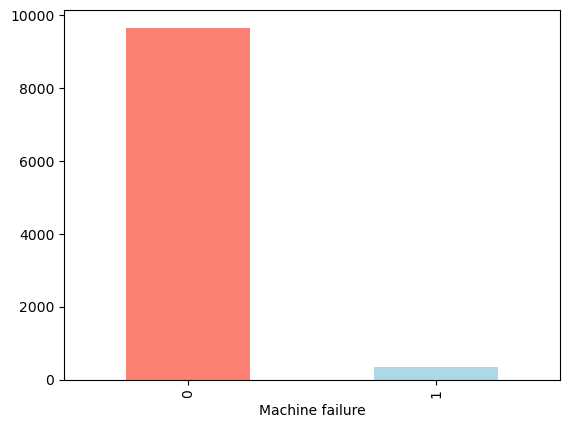

In [7]:
df["Machine failure"].value_counts().plot(kind="bar", color=["salmon", "lightblue"])

From the plot above, it shows that the dataset is highly imbalanced

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [17]:
from sklearn.model_selection import train_test_split

# seperating predictors from target and possible leakage columns
exclude = ["UDI", "Product ID", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df.drop(columns=exclude)
y = df["Machine failure"]

# 60% training data
# 20% validation
# 20% testing
X_train, X_validate, y_train, y_validate = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_validate, y_validate, test_size=0.5, random_state=42, stratify=y_validate)

# setting out the data exploration set
eda = X_train.copy()
eda["Machine failure"] = y_train

print(f"Training Observations {len(eda)}")
print(f"Missing Values {eda.isnull().sum()}")
print(f"Duplicate Rows {eda.duplicated().sum()}")

Training Observations 6000
Missing Values Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
dtype: int64
Duplicate Rows 0


In [18]:
eda.describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],6000.0,300.019783,2.004329,295.3,298.3,300.1,301.5,304.5
Process temperature [K],6000.0,310.012383,1.479536,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],6000.0,1538.869500,180.530086,1168.0,1422.0,1503.0,1614.0,2886.0
Torque [Nm],6000.0,40.034067,10.035769,3.8,33.2,40.1,46.9,76.6
Tool wear [min],6000.0,107.492833,63.571628,0.0,52.0,107.0,162.0,253.0
Machine failure,6000.0,0.033833,0.180815,0.0,0.0,0.0,0.0,1.0


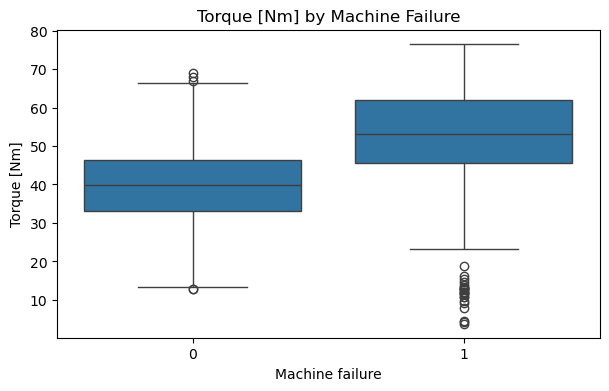

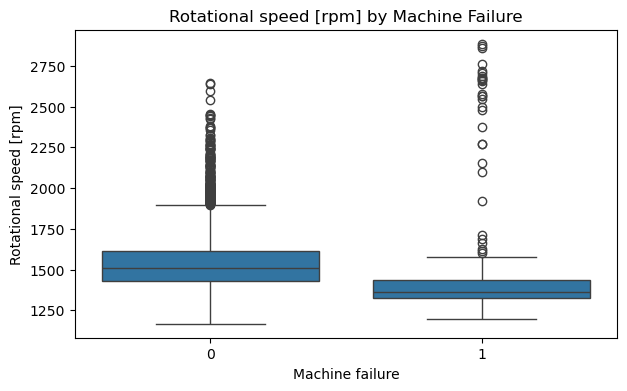

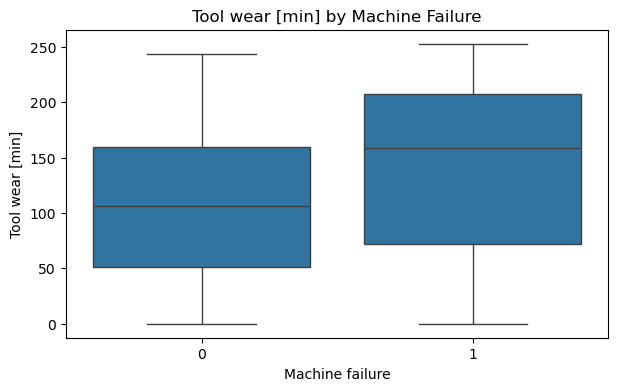

In [19]:
features = ["Torque [Nm]", "Rotational speed [rpm]", "Tool wear [min]"]

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda, x="Machine failure", y=feature)
    plt.title(f"{feature} by Machine Failure")

BoxPlot Findings (Torque vs Machine Failure):
* Machines experiencing failure generally have higher torque than machines operating normally, 
    but the failure group also contains severally unusually low torque observations
    This suggests that high torque isnt the only operating condition associated with failure.
* Rotational speed vs Machine Failure: The median rotational speed is lower for machines experiencing failure.
  This says that machines failure might occur under different operating conditions like; some failures could be associated with low rotational speeds      and high torque, while others could be associated with unusually high rotational speeds
* Tool Wear vs Machine Failure: Machinee experiencing failure tends to have higher tool wear. This consistent with the possibility that accumulated        wear contributes to certain failure conditions. some machines operate normally despite having high tool wear, while others experience failure with     relatively low wear. Tool wear might help to model identity failures, but it is unlikely to be sufficient on its own.

Do Machine failures cluster around a particular combination of torque and rotational speed?

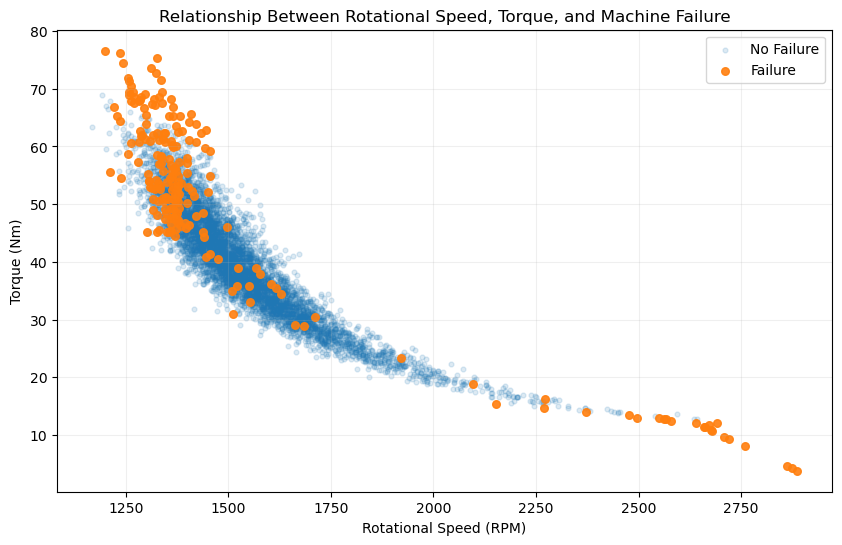

In [20]:
import matplotlib.pyplot as plt

normal = eda[eda["Machine failure"] == 0]
failed = eda[eda["Machine failure"] == 1]

plt.figure(figsize=(10, 6))

# Normal operating observations
plt.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.15,
    s=12,
    label="No Failure"
)

# Failure observations
plt.scatter(
    failed["Rotational speed [rpm]"],
    failed["Torque [Nm]"],
    alpha=0.9,
    s=30,
    label="Failure"
)

plt.title("Relationship Between Rotational Speed, Torque, and Machine Failure")
plt.xlabel("Rotational Speed (RPM)")
plt.ylabel("Torque (Nm)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

From the plot, its clear that Torque and Rotational speed have an inverse relationship; as torque increases, rotational speed decreases. Another observation is that machine failure happens at two extremes, the first extreme is the region where there is low rpm and high torque. the second extreme is the region where there is very high rpm and low torque

This means that torque and RPM alone cannot perfectly distinguish failed equipment from normally operating equipment. Theres need to consider other measurements such as temperature, tool wear, and equipment type.

The mechanical power equation:
 `P = rw`
 Since the rotational speed is measured in rpm; i can calculate mechanical power in watts:
 `P = (2*pi*N*T)/(60)`
 where:
 * P = Mechanical Power (watts)
 * N = rotational speed (rpm)
 * T = Torque (Nm)

I can create a new feature called Mechanical power [W]

In [21]:
eda["Mechanical power [W]"] = (2 * np.pi * eda["Rotational speed [rpm]"] * eda["Torque [Nm]"]) / 60

Instead of evaluating torque and RPM seperately, I can create a new feature representing their combined mechanical relationship. 
I can eventually compare model performance with and without the feature.
However, because the dataset is synthetic and some of its failure labels are generated using power-related conditions, improvement from this feature would partly reflect how the dataset was constructed.

### Modelling

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score

##### Logistic Regression

In [25]:
num_features = X_train.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns
cat_features = X_train.select_dtypes(include=["object", "category"]).columns

# Preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

# Pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

C:\Users\didigu\AppData\Local\Temp\ipykernel_10352\2273129515.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_train.select_dtypes(include=["object", "category"]).columns


In [26]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [27]:
y_preds = logistic_model.predict(X_val)

In [28]:
# Predict probabilities
y_prob = logistic_model.predict_proba(X_val)[:, 1]

In [30]:
# Evaluation
print(classification_report(y_val, y_preds, zero_division=0))

              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1932
           1       0.15      0.79      0.25        68

    accuracy                           0.84      2000
   macro avg       0.57      0.82      0.58      2000
weighted avg       0.96      0.84      0.89      2000



In [31]:
print("Average Precision:", round(average_precision_score(y_val, y_prob), 4))

Average Precision: 0.4072


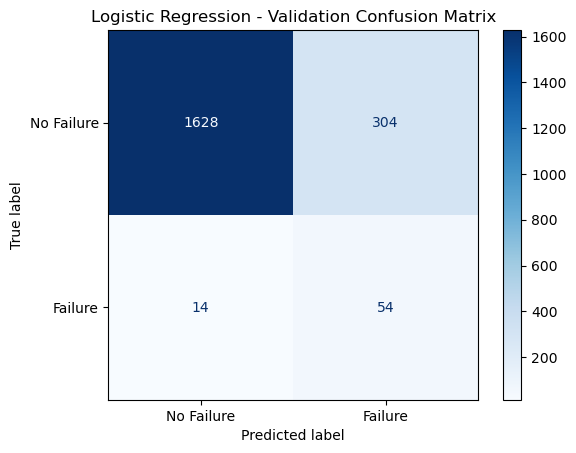

In [33]:
ConfusionMatrixDisplay.from_predictions(y_val, y_preds, display_labels=["No Failure", "Failure"], cmap="Blues")
plt.title("Logistic Regression: Validation Confusion Matrix")
plt.show()

* True Positives (54): Correctly identified machine failures.
* True Negatives (1,628): Correctly identified normal operating conditions.
* False Positives (304): Incorrectly predicted machine failures.
* False Negatives (14): Failed to identify actual machine failures.

In an industrial environment, false negatives could result in unexpected equipment downtime, while false positives could result in unnecessary maintenance inspections.

### Logistic Regression: Baseline Findings

The Logistic Regression model achieved a validation accuracy of 84.10%, recall of 79.41%, precision of 15.08%, and an average precision score of 0.4072.

Although the model successfully identified 54 out of 68 machine failures, it generated 304 false positives and missed 14 actual failures.

While the recall score approaches the project's initial target of 80%, the low precision indicates that the model generates an excessive number of false alarms.

Considering the nonlinear relationships observed during exploratory data analysis, more advanced classification algorithms will be investigated to improve predictive performance while maintaining high failure detection rates.

##### Random Forest Classifier

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.89      0.35      0.51        68

    accuracy                           0.98      2000
   macro avg       0.93      0.68      0.75      2000
weighted avg       0.97      0.98      0.97      2000

Average Precision: 0.7057


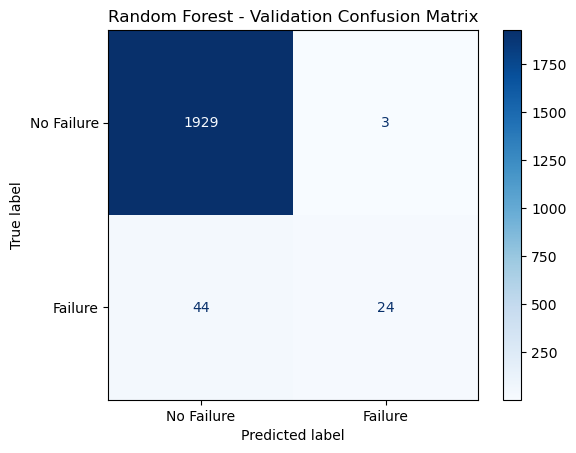

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

rf_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_val)
rf_probs = rf_model.predict_proba(X_val)[:, 1]

print(classification_report(y_val, rf_preds, zero_division=0))

print("Average Precision:",
      round(average_precision_score(y_val, rf_probs), 4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_preds,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Random Forest: Validation Confusion Matrix")
plt.show()

The Random Forest model has significantly improved precision, but it also introduced another problem: the model is missing too many actual machine failures. However, the Average Precision score suggests that Random Forest is a more promising model than Logistic Regression.
Random Forest substantially reduces false alarms, but it only identifies 24 of the 68 actual machine failures.

Before changing the algorithm or conducting hyperparameter tuning, i'd investigate classification threshold optimization.

By default, binary Random Forest classification generally uses a decision threshold of 0.5.
\[
y_hat = 
\begin{cases}
1 & P(\text{failure})>0.5\\
0 & P(\text{failure})\leq 0.5
\end{cases}
\]

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 1, 0.05)

results = []

for threshold in thresholds:

    predictions = (rf_probs >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions)
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1-score
0,0.05,0.316327,0.911765,0.469697
1,0.10,0.393103,0.838235,0.535211
2,0.15,0.510204,0.735294,0.602410
3,0.20,0.626667,0.691176,0.657343
4,0.25,0.698413,0.647059,0.671756
5,0.30,0.714286,0.588235,0.645161
6,0.35,0.787234,0.544118,0.643478
7,0.40,0.804878,0.485294,0.605505
8,0.45,0.828571,0.426471,0.563107
9,0.50,0.892857,0.367647,0.520833


By lowering the threshold, the model becomes more sensitive to potential failures.

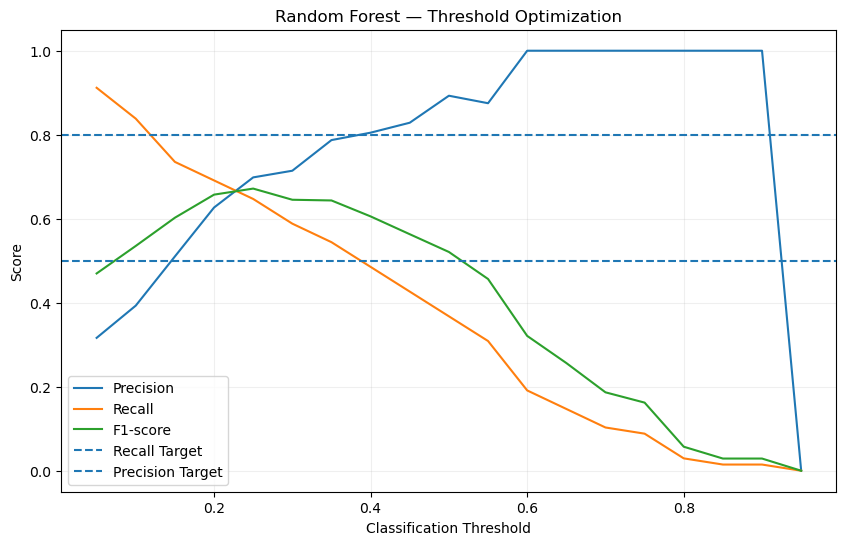

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(threshold_results["Threshold"],
         threshold_results["Precision"], label="Precision")

plt.plot(threshold_results["Threshold"],
         threshold_results["Recall"], label="Recall")

plt.plot(threshold_results["Threshold"],
         threshold_results["F1-score"], label="F1-score")

plt.axhline(y=0.8, linestyle="--", label="Recall Target")
plt.axhline(y=0.5, linestyle="--", label="Precision Target")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest: Threshold Optimization")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Classification Threshold Optimization: Findings

Lowering the classification threshold improved the Random Forest model's ability to identify machine failures at the expense of precision.

Among the tested thresholds, a threshold of 0.25 produced the highest F1-score of 0.6718, achieving a precision of 69.84% and a recall of 64.71%.

However, none of the tested thresholds simultaneously achieved the project's initial precision and recall objectives. Further experimentation through domain-informed feature engineering can be conducted to improve classification performance.

I created 2 new features rather than relying exclusively on machine learning algorithms

Temperature Difference = `Process Temperature * Air Temperature`; To investigate heat dissipation

Mechanical Strain Indicator = `Torque * Tool Wear`; To investigate wear-related operating stress

In [37]:
def engineer_features(data):
    data = data.copy()

    data["Mechanical Power"] = (
        2 * np.pi *
        data["Rotational speed [rpm]"] *
        data["Torque [Nm]"]
    ) / 60

    data["Temperature Difference"] = (
        data["Process temperature [K]"] -
        data["Air temperature [K]"]
    )

    data["Mechanical Strain Indicator"] = (
        data["Torque [Nm]"] *
        data["Tool wear [min]"]
    )

    return data

In [38]:
X_train_eng = engineer_features(X_train)
X_val_eng = engineer_features(X_val)

X_train_eng.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical Power,Temperature Difference,Mechanical Strain Indicator
3736,H,302.2,311.1,1628,30.6,105,5216.803097,8.9,3213.0
8772,L,297.5,308.6,1621,28.9,0,4905.795896,11.1,0.0
6622,L,301.7,310.7,1493,51.1,87,7989.310974,9.0,4445.7
9000,L,297.0,307.9,1493,46.1,173,7207.578002,10.9,7975.3
7604,L,300.4,311.3,1639,34.6,24,5938.594481,10.9,830.4


##### Training a random forest with engineered features

In [39]:
num_features_eng = X_train_eng.select_dtypes(
    include="number"
).columns

cat_features_eng = ["Type"]

preprocessor_eng = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features_eng),
        ("cat", OneHotEncoder(handle_unknown="ignore"), 
         cat_features_eng)
    ]
)

rf_model_eng = Pipeline(
    steps=[
        ("preprocessor", preprocessor_eng),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model_eng.fit(X_train_eng, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.96      0.69      0.80        68

    accuracy                           0.99      2000
   macro avg       0.97      0.85      0.90      2000
weighted avg       0.99      0.99      0.99      2000

Average Precision: 0.8398


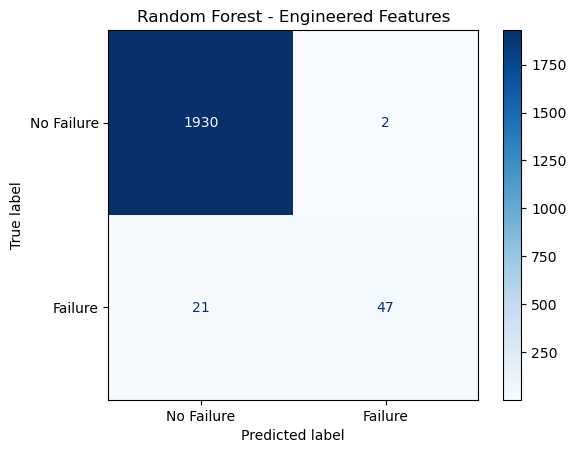

In [40]:
rf_preds_eng = rf_model_eng.predict(X_val_eng)

rf_probs_eng = rf_model_eng.predict_proba(X_val_eng)[:, 1]

print(classification_report(
    y_val, rf_preds_eng, zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_val, rf_probs_eng), 4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_preds_eng,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Random Forest: Engineered Features")
plt.show()

### Impact of Domain-Informed Feature Engineering

Three additional features were introduced based on engineering principles: mechanical power, temperature difference, and a torque–tool wear interaction indicator.

The introduction of these features significantly improved the Random Forest classifier's validation performance.

- Accuracy increased from 97.65% to 98.85%.
- Recall increased from 35.29% to 69.12%.
- Precision increased from 88.89% to 95.92%.
- F1-score increased from 0.5053 to 0.8034.
- Average precision increased from 0.7057 to 0.8398.

These results demonstrate the potential value of incorporating domain knowledge into machine learning workflows.

However, because the dataset is synthetic and the engineered features reflect some of its failure-generation mechanisms, these results do not establish real-world predictive reliability.

We have considerable room to sacrifice some precision in exchange for improved recall.

In [41]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, rf_probs_eng
)

threshold_results_eng = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision[:-1],
    "Recall": recall[:-1]
})

threshold_results_eng["F1-score"] = (
    2 * threshold_results_eng["Precision"] *
    threshold_results_eng["Recall"]
) / (
    threshold_results_eng["Precision"] +
    threshold_results_eng["Recall"]
)

# Find thresholds that meet both project objectives
eligible = threshold_results_eng[
    (threshold_results_eng["Precision"] >= 0.50) &
    (threshold_results_eng["Recall"] >= 0.80)
]

eligible.sort_values(
    by=["Recall", "Precision"],
    ascending=False
).head(10)

,Threshold,Precision,Recall,F1-score
20,0.100,0.523364,0.823529,0.640000
43,0.300,0.916667,0.808824,0.859375
42,0.275,0.901639,0.808824,0.852713
41,0.255,0.887097,0.808824,0.846154
40,0.250,0.859375,0.808824,0.833333
39,0.225,0.833333,0.808824,0.820896
38,0.215,0.820896,0.808824,0.814815
37,0.210,0.808824,0.808824,0.808824
36,0.205,0.797101,0.808824,0.802920
35,0.200,0.774648,0.808824,0.791367


Both targets have been achieved on validation data. Now we need to determine whether the model generalizes to unseen data.

### Final model evaluation

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.89      0.84      0.86        68

    accuracy                           0.99      2000
   macro avg       0.94      0.92      0.93      2000
weighted avg       0.99      0.99      0.99      2000

Average Precision: 0.8647


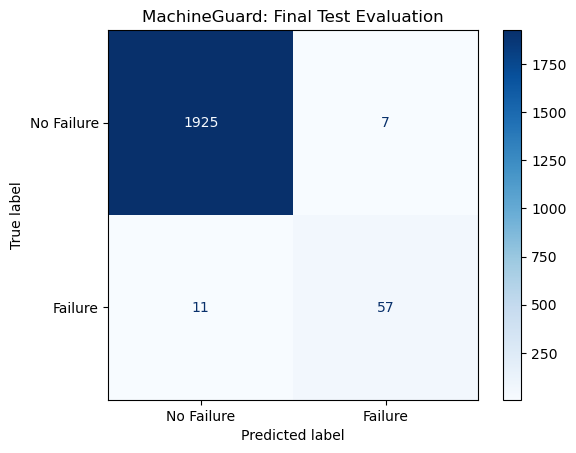

In [42]:
# Prepare unseen test data
X_test_eng = engineer_features(X_test)

# Selected classification threshold
final_threshold = 0.30

# Generate prediction probabilities
test_probs = rf_model_eng.predict_proba(X_test_eng)[:, 1]

# Apply selected threshold
test_preds = (test_probs >= final_threshold).astype(int)

# Evaluate final model
print(classification_report(
    y_test, test_preds, zero_division=0
))

print("Average Precision:",
      round(average_precision_score(y_test, test_probs), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_preds,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("MachineGuard: Final Test Evaluation")
plt.show()

### Final Model and Threshold Selection

The Random Forest classifier with domain-informed engineered features was selected as the final model.

A classification threshold of 0.30 was chosen based on validation performance, achieving 91.67% precision, 80.88% recall, and an F1-score of 0.8594.

The selected configuration satisfied both initial project objectives while maintaining a favorable balance between failure detection and false alarms.

The final model will be evaluated on an independent test dataset to assess its ability to generalize to unseen observations.

## Conclusion

MachineGuard explored the application of machine learning to industrial equipment failure classification using 10,000 synthetic machine operating observations.

Through exploratory data analysis, comparative modeling, domain-informed feature engineering, and classification threshold optimization, the final Random Forest classifier achieved:

- Accuracy: 99.10%
- Precision: 89.06%
- Recall: 83.82%
- F1-score: 0.8636
- Average Precision: 0.8647

The final model successfully met both initial project objectives, correctly identifying 57 out of 68 machine failures on an independent test dataset.

The results demonstrate the value of incorporating engineering principles into machine learning workflows and selecting evaluation metrics appropriate for imbalanced classification problems.

### Limitations and Future Work

- The model was trained on synthetically generated data.
- The current implementation identifies failure conditions rather than forecasting future failures.
- Further validation using real industrial equipment data is necessary.
- Future development could incorporate real-time sensor measurements, time-series modeling, and automated maintenance alerts.

### Saving the model

In [43]:
import joblib

joblib.dump({
    "model": rf_model_eng,
    "threshold": final_threshold
}, "machineguard_model.pkl")

['machineguard_model.pkl']